## Analyzing Lamine Yamal's Performances from Euros 2024 - Present
- The purpose of this small proyect is to answer the following question:
    - Does Yamal disappear in big games?

The analysis begins at the Euros 2024 since that is when Yamal really started becoming the biggest young star in the world.
Some now consider him the best player in the world. 

This will be divided into 2 sections:
- Setup
- Analysis 

# Setup

### We start by reading in the files and cleaning them before starting any sort of analysis
There are 3 files that cover 3 different seasons:
- yamal2425.csv: 2024-2025 season including the Euros 2024
- yamal2526.csv: 2025-2026 season 
- yamal2627.csv: 2026-2027 season 

Lets clean yamal2425 first. 
I am loading every file, so I dont have to load them later on in the notebook. 

In [484]:
import pandas as pd

def readCSV(name):
    df = pd.read_csv(name, parse_dates=["Date"])
    df = df.dropna(how="all") 
    return df

'''
This gets repetitive, so I'm making a function. though 6 lines isnt terrible. 
in the end, the function and variables ended up being 7 lines. but in the case
that there are more than 4 files, the function does do it in less lines. So if I wanted to 
analyze more seasons, this would end up saving some time / lines. As long as the files
have the same format.

df2425 = pd.read_csv("yamal2425.csv", parse_dates=["Date"])
df2425 = df2425.dropna(how="all")
df2526 = pd.read_csv("yamal2526.csv", parse_dates=["Date"])
df2526 = df2526.dropna(how="all")
df2627 = pd.read_csv("yamal2627.csv", parse_dates=["Date"])
df2627 = df2627.dropna(how="all")

'''

df2425 = readCSV("yamal2425.csv")
df2526 = readCSV("yamal2526.csv")
df2627 = readCSV("yamal2627.csv")

df2425.head()

,Date,Day,Comp,Round,Venue,Result,Squad,Opponent,Start,Pos,...,Fls,Fld,Off,Crs,TklW,Int,OG,PKwon,PKcon,Match Report
0,2024-06-15,Sat,UEFA Euro,Group stage,Neutral,W 3–0,es Spain,hr Croatia,Y,AM,...,1,0,1.0,3,1,0,0,NaN,NaN,Match Report
1,2024-06-20,Thu,UEFA Euro,Group stage,Neutral,W 1–0,es Spain,it Italy,Y,FW,...,1,0,0.0,2,1,0,0,NaN,NaN,Match Report
2,2024-06-24,Mon,UEFA Euro,Group stage,Neutral,W 1–0,es Spain,al Albania,N,NaN,...,0,1,0.0,1,1,0,0,NaN,NaN,Match Report
3,2024-06-30,Sun,UEFA Euro,Round of 16,Neutral,W 4–1,es Spain,ge Georgia,Y,FW,...,3,2,1.0,9,1,1,0,NaN,NaN,Match Report
4,2024-07-05,Fri,UEFA Euro,Quarter-finals,Neutral,W 2–1,es Spain,de Germany,Y,AM,...,0,1,0.0,0,3,2,0,NaN,NaN,Match Report


### Shortening the data frame by only using the columns that matter for this analysis
- Opponent
- Round
- Minutes
- Goals
- Assists
- etc

In [485]:
columns = ["Date", "Comp", "Round", "Venue", "Squad", "Opponent", "Min", "Gls", "Ast", "Sh", "SoT", "Crs"]
df2425 = df2425[columns]
df2526 = df2526[columns]
df2627 = df2627[columns]
df2425.info()

<class 'pandas.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      69 non-null     datetime64[us]
 1   Comp      69 non-null     str           
 2   Round     69 non-null     str           
 3   Venue     69 non-null     str           
 4   Squad     69 non-null     str           
 5   Opponent  69 non-null     str           
 6   Min       69 non-null     int64         
 7   Gls       69 non-null     int64         
 8   Ast       69 non-null     int64         
 9   Sh        69 non-null     int64         
 10  SoT       69 non-null     int64         
 11  Crs       69 non-null     int64         
dtypes: datetime64[us](1), int64(6), str(5)
memory usage: 6.6 KB


In [486]:
df2425.isna().sum() # total na (not a number) values

Date        0
Comp        0
Round       0
Venue       0
Squad       0
Opponent    0
Min         0
Gls         0
Ast         0
Sh          0
SoT         0
Crs         0
dtype: int64

In [487]:
df2425.describe() # checking the values to see if their mean, max and min make sense with the data in the table

,Date,Min,Gls,Ast,Sh,SoT,Crs
count,69,69.000000,69.000000,69.000000,69.000000,69.000000,69.000000
mean,2024-12-28 13:54:46.956521,81.710145,0.318841,0.376812,3.840580,1.463768,2.869565
min,2024-06-15 00:00:00,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2024-09-28 00:00:00,75.000000,0.000000,0.000000,3.000000,1.000000,1.000000
50%,2025-01-18 00:00:00,89.000000,0.000000,0.000000,4.000000,1.000000,2.000000
75%,2025-03-30 00:00:00,90.000000,1.000000,1.000000,5.000000,2.000000,3.000000
max,2025-06-08 00:00:00,120.000000,2.000000,2.000000,10.000000,5.000000,11.000000
std,NaN,18.367251,0.528393,0.545070,2.083713,1.170466,2.454965


### Checking if the values in the data frame / table add up to the total
- Goals: 22
- Assists: 26
- Shots: 265
- Shots on Target: 101
- Crosses: 198

In [488]:
df2425["Gls"].sum() 

np.int64(22)

In [489]:
df2425["Ast"].sum()

np.int64(26)

In [490]:
df2425["Sh"].sum()

np.int64(265)

In [491]:
df2425["SoT"].sum()

np.int64(101)

In [492]:
df2425["Crs"].sum()

np.int64(198)

### Now that the values are correct, let's clean the country codes
On the table, countries have a code before the actual name.
For example, "es Spain" and "de Germany"

first let's check every team's name so we know what to remove

In [493]:
df2425["Opponent"].unique()

<StringArray>
[      'hr Croatia',         'it Italy',       'al Albania',
       'ge Georgia',       'de Germany',        'fr France',
      'eng England',         'Valencia',    'Athletic Club',
   'Rayo Vallecano',       'Valladolid',        'rs Serbia',
   'ch Switzerland',           'Girona',        'fr Monaco',
       'Villarreal',           'Getafe',          'Osasuna',
    'ch Young Boys',           'Alavés',       'dk Denmark',
          'Sevilla', 'de Bayern Munich',      'Real Madrid',
         'Espanyol',      'rs Red Star',       'Las Palmas',
         'Mallorca',       'Real Betis',      'de Dortmund',
          'Leganés',       'pt Benfica',      'it Atalanta',
  'Atlético Madrid',    'Real Sociedad',   'nl Netherlands',
       'Celta Vigo',         'it Inter',      'pt Portugal']
Length: 39, dtype: str

We can see that theres multiple teams with this preceding code.
The longest preceding code is 3 characters long, and they are all lowercase.
To remove these, we replace the preceding code with an empty string using regex:


In [494]:
df2425["Opponent"].str.replace("^[a-z]{2,3} ", "", regex=True)

0           Croatia
1             Italy
2           Albania
3           Georgia
4           Germany
          ...      
64         Espanyol
65       Villarreal
66    Athletic Club
67           France
68         Portugal
Name: Opponent, Length: 69, dtype: str

In [495]:
df2425.head()

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs
0,2024-06-15,UEFA Euro,Group stage,Neutral,es Spain,hr Croatia,85,0,1,3,1,3
1,2024-06-20,UEFA Euro,Group stage,Neutral,es Spain,it Italy,70,0,0,1,0,2
2,2024-06-24,UEFA Euro,Group stage,Neutral,es Spain,al Albania,19,0,0,0,0,1
3,2024-06-30,UEFA Euro,Round of 16,Neutral,es Spain,ge Georgia,90,0,1,7,2,9
4,2024-07-05,UEFA Euro,Quarter-finals,Neutral,es Spain,de Germany,62,0,1,2,1,0


That didnt change anything in the original, as seen by using .head() to see the first five values. So we have to properly replace the original with the change. 
To do this:

In [496]:
df2425["Opponent"] = df2425["Opponent"].str.replace("^[a-z]{2,3} ", "", regex=True)
df2425["Opponent"]

0           Croatia
1             Italy
2           Albania
3           Georgia
4           Germany
          ...      
64         Espanyol
65       Villarreal
66    Athletic Club
67           France
68         Portugal
Name: Opponent, Length: 69, dtype: str

Now we do the same for df2425["Squad"] to remove "es" from Spain.

In [497]:
df2425["Squad"] = df2425["Squad"].str.replace("^[a-z]{2,3} ", "", regex=True)
df2425["Squad"]

0         Spain
1         Spain
2         Spain
3         Spain
4         Spain
        ...    
64    Barcelona
65    Barcelona
66    Barcelona
67        Spain
68        Spain
Name: Squad, Length: 69, dtype: str

In [498]:
df2425["Opponent"].unique()

<StringArray>
[        'Croatia',           'Italy',         'Albania',         'Georgia',
         'Germany',          'France',         'England',        'Valencia',
   'Athletic Club',  'Rayo Vallecano',      'Valladolid',          'Serbia',
     'Switzerland',          'Girona',          'Monaco',      'Villarreal',
          'Getafe',         'Osasuna',      'Young Boys',          'Alavés',
         'Denmark',         'Sevilla',   'Bayern Munich',     'Real Madrid',
        'Espanyol',        'Red Star',      'Las Palmas',        'Mallorca',
      'Real Betis',        'Dortmund',         'Leganés',         'Benfica',
        'Atalanta', 'Atlético Madrid',   'Real Sociedad',     'Netherlands',
      'Celta Vigo',           'Inter',        'Portugal']
Length: 39, dtype: str

In [499]:
df2425["Squad"].unique()

<StringArray>
['Spain', 'Barcelona']
Length: 2, dtype: str

### Thats it for cleaning the 24/25 season
- Now the same steps for the other 2 seasons. Some were done simultaneously in previous cells. 
- Check if the values add up correctly and if the preceding code is gone for squads.
- Totals can be found on the README file. 

In [500]:
# small function to not write the same thing multiple times.
# could be a better function, dynamic for any data set by asking for the specific index
# as an argument. But this works for the dataset im using

def removePreceding(df):
    df["Opponent"] = df["Opponent"].str.replace("^[a-z]{2,3} ", "", regex=True)
    df["Squad"] = df["Squad"].str.replace("^[a-z]{2,3} ", "", regex=True)

removePreceding(df2526)
removePreceding(df2627)
df2526["Opponent"].unique()

<StringArray>
[       'Mallorca',         'Levante',  'Rayo Vallecano',        'Bulgaria',
         'Türkiye',   'Real Sociedad',        'Paris SG',          'Girona',
      'Olympiacos',     'Real Madrid',           'Elche',     'Club Brugge',
      'Celta Vigo',   'Athletic Club',         'Chelsea',          'Alavés',
 'Atlético Madrid',      'Real Betis',       'Frankfurt',         'Osasuna',
     'Guadalajara',      'Villarreal',        'Espanyol',     'Racing Sant',
          'Oviedo',   'FC Copenhagen',        'Albacete',       'Newcastle',
         'Sevilla',          'Serbia',           'Egypt',      'Cabo Verde',
    'Saudi Arabia',         'Uruguay',         'Austria',        'Portugal',
         'Belgium',          'France',       'Argentina']
Length: 39, dtype: str

In [501]:
df2526["Squad"].unique()

<StringArray>
['Barcelona', 'Spain']
Length: 2, dtype: str

In [502]:
# making a function for the sums so it doesnt take 5+ cells
def totalSums(df):
    print("Total Goals:", df["Gls"].sum())
    print("Total Assists:", df["Ast"].sum())
    print("Total Shots:", df["Sh"].sum())
    print("Total Shots on Target:", df["SoT"].sum())
    print("Total Crosses:", df["Crs"].sum())

In [503]:
totalSums(df2526)

Total Goals: 25
Total Assists: 20
Total Shots: 206.0
Total Shots on Target: 74.0
Total Crosses: 192.0


In [504]:
totalSums(df2627)

Total Goals: 17
Total Assists: 13
Total Shots: 97
Total Shots on Target: 29
Total Crosses: 54


### Stacking each table on top of each other and adding a season column
- This could have been done from the beginning
- stacking everything together and using just one table
- however, since this project is mostly for me to learn and practice,
I did operations on all three

First, add the season column to all 3 tables

In [505]:
df2425["Season"] = "24/25"
df2526["Season"] = "25/26"
df2627["Season"] = "26/27"

df2425["Season"]

0     24/25
1     24/25
2     24/25
3     24/25
4     24/25
      ...  
64    24/25
65    24/25
66    24/25
67    24/25
68    24/25
Name: Season, Length: 69, dtype: str

Now that season is added, stack all 3 tables

In [506]:
df = pd.concat([df2425, df2526, df2627], ignore_index=True)
df

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs,Season
0,2024-06-15,UEFA Euro,Group stage,Neutral,Spain,Croatia,85,0,1,3.0,1.0,3.0,24/25
1,2024-06-20,UEFA Euro,Group stage,Neutral,Spain,Italy,70,0,0,1.0,0.0,2.0,24/25
2,2024-06-24,UEFA Euro,Group stage,Neutral,Spain,Albania,19,0,0,0.0,0.0,1.0,24/25
3,2024-06-30,UEFA Euro,Round of 16,Neutral,Spain,Georgia,90,0,1,7.0,2.0,9.0,24/25
4,2024-07-05,UEFA Euro,Quarter-finals,Neutral,Spain,Germany,62,0,1,2.0,1.0,0.0,24/25
...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,2026-10-20,Champions Lg,League phase,Away,Barcelona,Paris SG,90,1,0,4.0,1.0,1.0,26/27
142,2026-10-25,La Liga,Matchweek 10,Home,Barcelona,Real Madrid,90,0,0,5.0,0.0,2.0,26/27
143,2026-10-31,La Liga,Matchweek 11,Home,Barcelona,Alavés,73,2,1,6.0,3.0,1.0,26/27
144,2026-11-03,Champions Lg,League phase,Home,Barcelona,Aston Villa,90,1,0,6.0,3.0,2.0,26/27


## Checking for any invalid data

In [507]:
df.isna().sum()

Date        0
Comp        0
Round       0
Venue       0
Squad       0
Opponent    0
Min         0
Gls         0
Ast         0
Sh          2
SoT         2
Crs         2
Season      0
dtype: int64

There are 2games with invalid data or data not present. 
Which games are they?

In [508]:
df[df.isna().any(axis=1)]

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs,Season
111,2026-03-27,Friendlies (M),Friendlies (M),Home,Spain,Serbia,62,0,0,NaN,NaN,NaN,25/26
112,2026-03-31,Friendlies (M),Friendlies (M),Home,Spain,Egypt,45,0,0,NaN,NaN,NaN,25/26


Two friendlies from the 25/26 season do not have full data. Since they are friendly games, and yamal
did not score on any of them, they dont affect the data, so I can remove them or just ignore them.
- In this case, I will remove them. for practice.

In [509]:
df = df.dropna().reset_index(drop=True) # drops every row containing any number of NaN values. reset_index makes sure the indexes are correct after dropping, removing any gaps
df.isna().sum()

Date        0
Comp        0
Round       0
Venue       0
Squad       0
Opponent    0
Min         0
Gls         0
Ast         0
Sh          0
SoT         0
Crs         0
Season      0
dtype: int64

Above, the rows removed were 111, and 112. Check for correct indexing by looking at index 111

In [510]:
df.iloc[111]

Date        2026-04-04 00:00:00
Comp                    La Liga
Round              Matchweek 30
Venue                      Away
Squad                 Barcelona
Opponent        Atlético Madrid
Min                          90
Gls                           0
Ast                           0
Sh                          7.0
SoT                         0.0
Crs                         5.0
Season                    25/26
Name: 111, dtype: object

All data was stacked together, check if the totals are still the same. 
I will use the function I made above

In [511]:
totalSums(df.groupby("Season"))

Total Goals: Season
24/25    22
25/26    25
26/27    17
Name: Gls, dtype: int64
Total Assists: Season
24/25    26
25/26    20
26/27    13
Name: Ast, dtype: int64
Total Shots: Season
24/25    265.0
25/26    206.0
26/27     97.0
Name: Sh, dtype: float64
Total Shots on Target: Season
24/25    101.0
25/26     74.0
26/27     29.0
Name: SoT, dtype: float64
Total Crosses: Season
24/25    198.0
25/26    192.0
26/27     54.0
Name: Crs, dtype: float64


Now that the data is clean, stacked, and correct, we can start the analysis

# Analysis

### Does Yamal disappear in big games? 

To answer the question, we first have to figure out what counts as a big game. 
Is it only games against big teams? or is it also depending on the tournament's round? 

I will consider a big game as the following:
- A game against a big team, no matter the round.
- A game in the KO stages starting at the quarterfinals, no matter the team. Ever since Yamal started being essential for both spain and barcelona, they have made it to at least the qfs. That is the reason I am considering qfs or further important games. 

I will look at the data in the important games and compare it to the rest of the games. This is to further analyze if the player really disappears, or if he just does not show up at all, regardless of the game. Or viceversa, to see if the player appears on big games, but also appears in the rest. 

### First, let's find the games and separate them depending on importance
The way I define a big game is mentioned above, but what defines a big team? 

In this case, big teams are the following:
- National Teams on the top 20 FIFA rankings. Considering there are 211 countries on the rankings, around the top 10% sounds fair to be classified as a big team.
- The top teams of the top 5 european leagues. Premier League, Bundesliga, La Liga, Serie A, Ligue 1

To separate these teams from the rest, I will make a new column and name it importance. 

It will have two ways to lable the game: 
- B: Big game
- M: Minor game

Then, labeling will be determined as follows:
- If a team is one of the top teams, "Importance" will have a B.
- If the game is a knockout stage game (qf or further), it will have a B.
- Else it will have an M. 

In [512]:
import numpy as np
import matplotlib.pyplot as plt

In [513]:
df["Opponent"].unique()

<StringArray>
[        'Croatia',           'Italy',         'Albania',         'Georgia',
         'Germany',          'France',         'England',        'Valencia',
   'Athletic Club',  'Rayo Vallecano',      'Valladolid',          'Serbia',
     'Switzerland',          'Girona',          'Monaco',      'Villarreal',
          'Getafe',         'Osasuna',      'Young Boys',          'Alavés',
         'Denmark',         'Sevilla',   'Bayern Munich',     'Real Madrid',
        'Espanyol',        'Red Star',      'Las Palmas',        'Mallorca',
      'Real Betis',        'Dortmund',         'Leganés',         'Benfica',
        'Atalanta', 'Atlético Madrid',   'Real Sociedad',     'Netherlands',
      'Celta Vigo',           'Inter',        'Portugal',         'Levante',
        'Bulgaria',         'Türkiye',        'Paris SG',      'Olympiacos',
           'Elche',     'Club Brugge',         'Chelsea',       'Frankfurt',
     'Guadalajara',     'Racing Sant',          'Oviedo',   'F

In [514]:
# from the unique teams above, I will make the list
# naming is consistent all along, so there is no nead to change anything
bigTeams = {
    "Argentina", "Croatia", "Switzerland", "Uruguay", "Italy", "France", "England",
    "Portugal", "Netherlands", 

    "Real Madrid", "Atlético Madrid", "Bayern Munich", "Chelsea", "Dortmund", "Inter", 
    "Monaco", "Paris SG", "Real Betis", "Athletic Club"
}

koStages = {
    "Quarter-finals", "Semi-finals", "Final"
}


df["Importance"] = np.where(df["Opponent"].isin(bigTeams) | df["Round"].isin(koStages), 'B', 'M')
df

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs,Season,Importance
0,2024-06-15,UEFA Euro,Group stage,Neutral,Spain,Croatia,85,0,1,3.0,1.0,3.0,24/25,B
1,2024-06-20,UEFA Euro,Group stage,Neutral,Spain,Italy,70,0,0,1.0,0.0,2.0,24/25,B
2,2024-06-24,UEFA Euro,Group stage,Neutral,Spain,Albania,19,0,0,0.0,0.0,1.0,24/25,M
3,2024-06-30,UEFA Euro,Round of 16,Neutral,Spain,Georgia,90,0,1,7.0,2.0,9.0,24/25,M
4,2024-07-05,UEFA Euro,Quarter-finals,Neutral,Spain,Germany,62,0,1,2.0,1.0,0.0,24/25,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,2026-10-20,Champions Lg,League phase,Away,Barcelona,Paris SG,90,1,0,4.0,1.0,1.0,26/27,B
140,2026-10-25,La Liga,Matchweek 10,Home,Barcelona,Real Madrid,90,0,0,5.0,0.0,2.0,26/27,B
141,2026-10-31,La Liga,Matchweek 11,Home,Barcelona,Alavés,73,2,1,6.0,3.0,1.0,26/27,M
142,2026-11-03,Champions Lg,League phase,Home,Barcelona,Aston Villa,90,1,0,6.0,3.0,2.0,26/27,M


#### Goals + Assist Column
For the final setup step, I will create a goals+assists column. 

In [515]:
df["G/A"] = df["Gls"] + df["Ast"]
df

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs,Season,Importance,G/A
0,2024-06-15,UEFA Euro,Group stage,Neutral,Spain,Croatia,85,0,1,3.0,1.0,3.0,24/25,B,1
1,2024-06-20,UEFA Euro,Group stage,Neutral,Spain,Italy,70,0,0,1.0,0.0,2.0,24/25,B,0
2,2024-06-24,UEFA Euro,Group stage,Neutral,Spain,Albania,19,0,0,0.0,0.0,1.0,24/25,M,0
3,2024-06-30,UEFA Euro,Round of 16,Neutral,Spain,Georgia,90,0,1,7.0,2.0,9.0,24/25,M,1
4,2024-07-05,UEFA Euro,Quarter-finals,Neutral,Spain,Germany,62,0,1,2.0,1.0,0.0,24/25,B,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,2026-10-20,Champions Lg,League phase,Away,Barcelona,Paris SG,90,1,0,4.0,1.0,1.0,26/27,B,1
140,2026-10-25,La Liga,Matchweek 10,Home,Barcelona,Real Madrid,90,0,0,5.0,0.0,2.0,26/27,B,0
141,2026-10-31,La Liga,Matchweek 11,Home,Barcelona,Alavés,73,2,1,6.0,3.0,1.0,26/27,M,3
142,2026-11-03,Champions Lg,League phase,Home,Barcelona,Aston Villa,90,1,0,6.0,3.0,2.0,26/27,M,1


### Now that everything is set on the table, the real analysis of Yamal's performances can start
This analysis will be divided in 2 sections:
- Goals and Assists
- Are goals and assists enough to answer the question?

#### Goals and Assists
I will start by looking at the stats most people care about, his goals and assists. 
- total goals 
- total assists 
- total g/a 
- goals per 90 mins
- assists per 90 mins

I will look at his average in big games AND minor games, and compare them to each other.

To do so, I will divide the table into 2 tables. One for big games, one for minor games. 

In [516]:
dfB = df[df["Importance"] == 'B']
dfM =  df[df["Importance"] == 'M']
dfB

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs,Season,Importance,G/A
0,2024-06-15,UEFA Euro,Group stage,Neutral,Spain,Croatia,85,0,1,3.0,1.0,3.0,24/25,B,1
1,2024-06-20,UEFA Euro,Group stage,Neutral,Spain,Italy,70,0,0,1.0,0.0,2.0,24/25,B,0
4,2024-07-05,UEFA Euro,Quarter-finals,Neutral,Spain,Germany,62,0,1,2.0,1.0,0.0,24/25,B,1
5,2024-07-09,UEFA Euro,Semi-finals,Neutral,Spain,France,89,1,0,3.0,1.0,2.0,24/25,B,1
6,2024-07-14,UEFA Euro,Final,Neutral,Spain,England,88,0,1,2.0,2.0,6.0,24/25,B,1
8,2024-08-24,La Liga,Matchweek 2,Home,Barcelona,Athletic Club,89,1,0,2.0,1.0,2.0,24/25,B,1
12,2024-09-08,UEFA Nations League,League A,Away,Spain,Switzerland,45,0,1,1.0,1.0,1.0,24/25,B,1
14,2024-09-19,Champions Lg,League phase,Away,Barcelona,Monaco,79,1,0,2.0,1.0,1.0,24/25,B,1
22,2024-10-23,Champions Lg,League phase,Home,Barcelona,Bayern Munich,84,0,1,1.0,0.0,1.0,24/25,B,1
23,2024-10-26,La Liga,Matchweek 11,Away,Barcelona,Real Madrid,90,1,0,4.0,3.0,2.0,24/25,B,1


In [517]:
dfM

,Date,Comp,Round,Venue,Squad,Opponent,Min,Gls,Ast,Sh,SoT,Crs,Season,Importance,G/A
2,2024-06-24,UEFA Euro,Group stage,Neutral,Spain,Albania,19,0,0,0.0,0.0,1.0,24/25,M,0
3,2024-06-30,UEFA Euro,Round of 16,Neutral,Spain,Georgia,90,0,1,7.0,2.0,9.0,24/25,M,1
7,2024-08-17,La Liga,Matchweek 1,Away,Barcelona,Valencia,85,0,1,4.0,1.0,0.0,24/25,M,1
9,2024-08-27,La Liga,Matchweek 3,Away,Barcelona,Rayo Vallecano,89,0,1,5.0,1.0,3.0,24/25,M,1
10,2024-08-31,La Liga,Matchweek 4,Home,Barcelona,Valladolid,90,0,2,0.0,0.0,1.0,24/25,M,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,2026-10-03,UEFA Nations League,League A,Home,Spain,Czechia,45,1,0,2.0,1.0,3.0,26/27,M,1
136,2026-10-10,La Liga,Matchweek 8,Home,Barcelona,Getafe,90,0,1,6.0,0.0,7.0,26/27,M,1
137,2026-10-13,Champions Lg,League phase,Away,Barcelona,Galatasaray,90,0,2,5.0,0.0,4.0,26/27,M,2
141,2026-10-31,La Liga,Matchweek 11,Home,Barcelona,Alavés,73,2,1,6.0,3.0,1.0,26/27,M,3


The tables are now separated. We can start looking at his goals and assists

In [518]:
bGoals = dfB["Gls"].sum()
bAssists = dfB["Ast"].sum()
bMinutes = dfB["Min"].sum()
bGoals

np.int64(24)

In [519]:
bAssists

np.int64(18)

In [520]:
bMinutes

np.int64(5037)

In [521]:
bGPer90 = (bGoals/bMinutes)*90
bGPer90.round(2)
bGPer90

np.float64(0.4288266825491364)

In [522]:
bAPer90 = (bAssists/bMinutes)*90
bAPer90

np.float64(0.3216200119118523)

In [523]:
mGoals = dfM["Gls"].sum()
mAssists = dfM["Ast"].sum()
mMinutes = dfM["Min"].sum()
mGoals

np.int64(40)

In [524]:
mAssists

np.int64(41)

In [525]:
mMinutes

np.int64(6686)

In [526]:
mGPer90 = (mGoals/mMinutes)*90
mGPer90

np.float64(0.5384385282680227)

In [527]:
mAPer90 = (mAssists/mMinutes)*90
mAPer90

np.float64(0.5518994914747233)

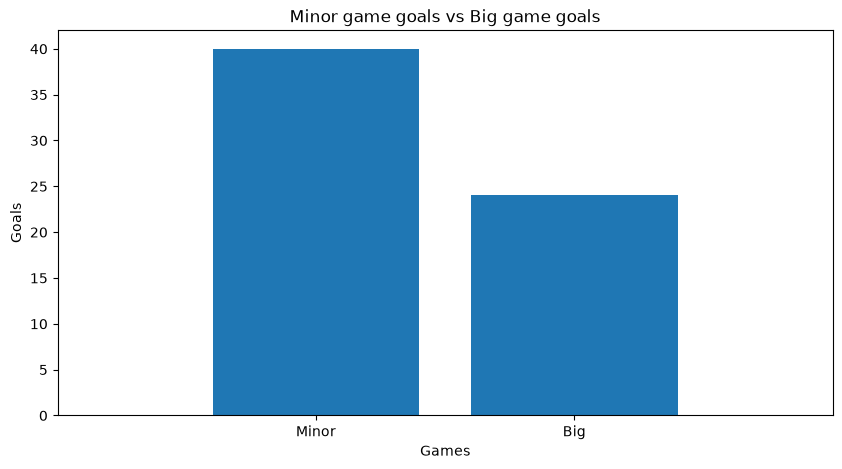

In [528]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["Minor", "Big"], [mGoals, bGoals])
ax.set_title("Minor game goals vs Big game goals")
ax.set_xlabel("Games")
ax.set_ylabel("Goals")
plt.xlim(-1,2)
plt.show()

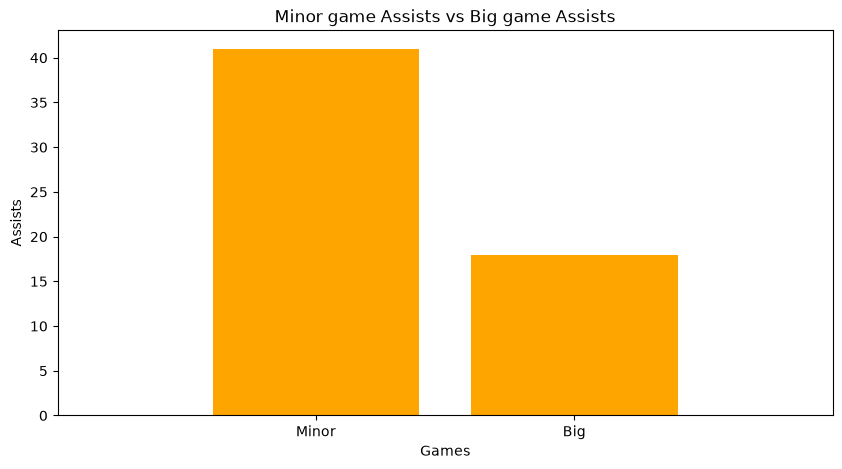

In [529]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["Minor", "Big"], [mAssists, bAssists], color="orange")
ax.set_title("Minor game Assists vs Big game Assists")
ax.set_xlabel("Games")
ax.set_ylabel("Assists")
plt.xlim(-1,2)
plt.show()

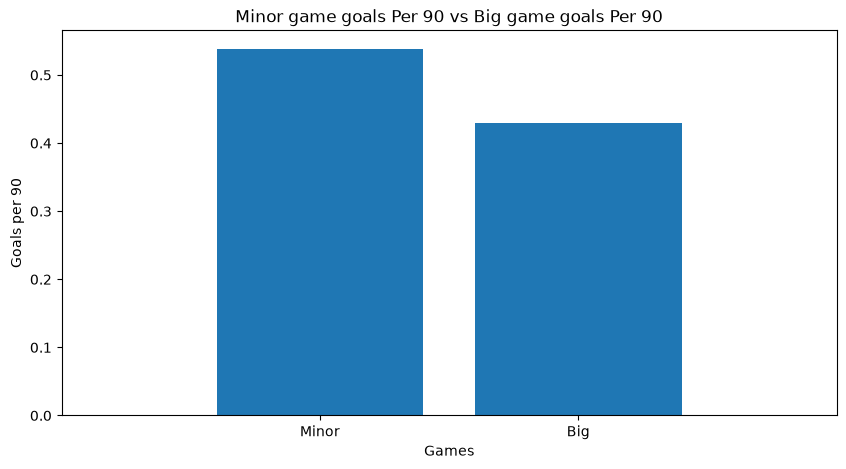

In [530]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["Minor", "Big"], [mGPer90, bGPer90])
ax.set_title("Minor game goals Per 90 vs Big game goals Per 90")
ax.set_xlabel("Games")
ax.set_ylabel("Goals per 90")
plt.xlim(-1,2)
plt.show()

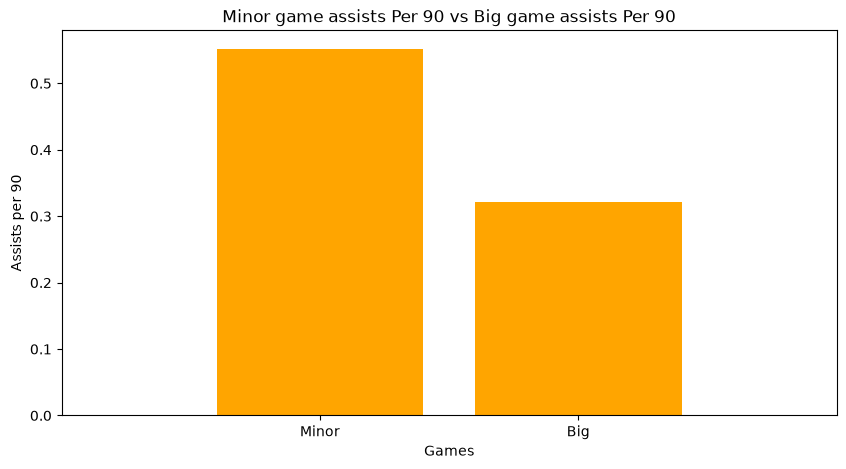

In [531]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["Minor", "Big"], [mAPer90, bAPer90], color="orange")
ax.set_title("Minor game assists Per 90 vs Big game assists Per 90")
ax.set_xlabel("Games")
ax.set_ylabel("Assists per 90")
plt.xlim(-1,2)
plt.show()

##### When looking at his goals and assists, Yamal clearly has way more in minor games than bigger games.
- Minor: 40 goals, 41 assists
- Big: 24 goals, 18 assists

His goals and assists per 90 minutes are also higher in minor games. 

So based on this alone, the answer is that Lamine does not show up as much in big games compared to minor games.

However, lets look at it in a different way. Still looking at goals and assists.  

##### Favorite Opponents

From the tables above, we can tell that there are much more minor games than bigger games. So instead of looking only at the totals, lets look at where these goals and assists came from. What opponents does he score and assist against the most?

In [532]:
favoriteTeams = df.groupby("Opponent")["G/A"].sum().sort_values(ascending=False)
top10 = favoriteTeams.head(10)
top10

Opponent
Atlético Madrid    6
Espanyol           6
Real Betis         6
Villarreal         6
Valencia           5
Real Madrid        5
Athletic Club      5
Alavés             5
Rayo Vallecano     4
Racing Sant        4
Name: G/A, dtype: int64

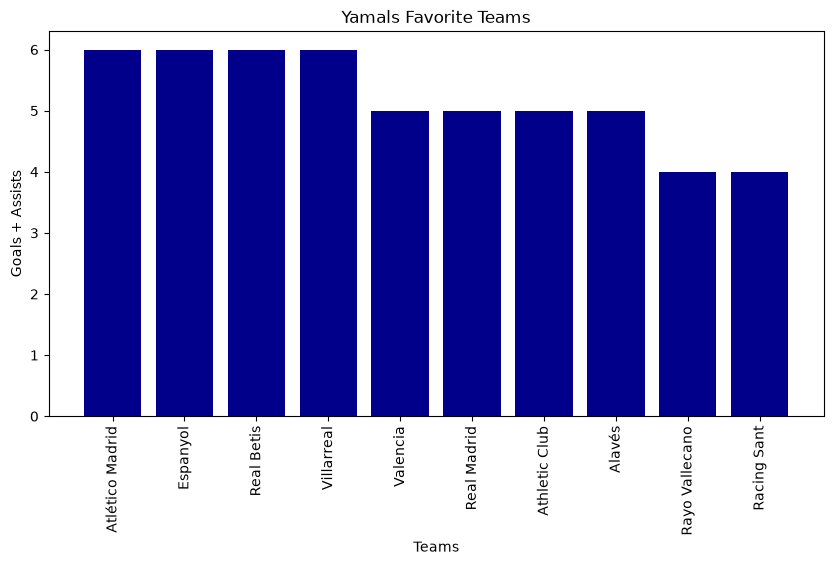

In [533]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(top10.index, top10.values, color="darkblue")
ax.set_title("Yamals Favorite Teams")
ax.set_xlabel("Teams")
ax.set_ylabel("Goals + Assists")
plt.xticks(rotation=90)
plt.show()

Big Games: 
- Atletico Madrid: 6 G/A
- Real Madrid: 5 G/A
- Real Betis: 6 G/A
- Athletic Club: 5 G/A
- Total: 29 G/A

Minor Games:
- Espanyol: 6 G/A
- Villareal: 6 G/A
- Valencia: 5 G/A
- Alaves: 5 G/A
- Rayo: 4 G/A
- Racing: 4 G/A
- Total: 30 G/A

As we can see from these results, he has 59 Goals and assists against his top 10 favorite teams. 29 come against bigger teams with 2 less games. And if we want to add villareal to it considering they have qualified to the champions league for 2 seasons in a row, that makes it 35 G/A for big games and 24 G/A for small games. 

When looking at it this way, he does show up in the big stage. If we add 5 more teams to this list, 2 of them are France and Croatia, with 7 G/A combined against them. This shows that not only does he show up for his club, he shows up for his national team. 

What about the champions league? His favorite teams are from Spain, but how does he do internationally?

##### Champions League

In [534]:
uclGA = df[df["Comp"] == "Champions Lg"]["G/A"].sum()
uclGA

np.int64(25)

In [535]:
uclGAperTeam = df[df["Comp"] == "Champions Lg"].groupby("Opponent")["G/A"].sum().sort_values(ascending=False)
uclGAperTeam

Opponent
Feyenoord          3
Newcastle          3
Dortmund           2
Galatasaray        2
Olympiacos         2
FC Copenhagen      2
Benfica            2
Atlético Madrid    1
Atalanta           1
Aston Villa        1
Bayern Munich      1
Monaco             1
Frankfurt          1
Club Brugge        1
Inter              1
Paris SG           1
Chelsea            0
Red Star           0
Young Boys         0
Name: G/A, dtype: int64

Yamal has scored or assisted against every team he has played against in the champions league since the 24/25 season, except for 3. 

Against big teams he has 7 G/A out of the 25 in total. 

Anyone who watched the Semifinals against inter and the quarter finals against atletico can tell that these stats are misleading. Only 1 G/A against atletico and inter? Yes, but he did much more than that. This analysis is only based on G/A though. 

Which of these came from important knockout games? qf and up. 

In [536]:
df[(df["Comp"] == "Champions Lg") & (df["Round"].isin(koStages))].groupby("Opponent")["G/A"].sum()

Opponent
Atlético Madrid    1
Dortmund           1
Inter              1
Name: G/A, dtype: int64

He showed up when it mattered. But it was not enough for Barcelona to go through. And based purely on G/A, he did show up. Scoring against the 3 opponents. 

If we want to add the round of 16:

In [537]:
df[(df["Comp"] == "Champions Lg") & (df["Round"] == "Round of 16")].groupby("Opponent")["G/A"].sum()

Opponent
Benfica      2
Newcastle    3
Name: G/A, dtype: int64

That adds 5 more G/A in the knockout stages. That is 8 G/A in total. He has scored or assisted in every KO round since the 24/25 season. Thats 2 seasons in a row. 

So as we can see, if we dive deeper to how the Goals and Assists were distributed, Yamal does show up when it matters. 

#### Are Goals and Assists enough?
By looking at G/A alone and looking at what games they came from. We were able to see that Yamal does show up in big games.

However, for the sake of practice and more analysis, lets look at one extra data provided by the data set:
- Shots on Target

This will show us his conversion rate in big games and minor games.

In [538]:
bOnTarget = dfB["SoT"].sum()
bOnTarget

np.float64(78.0)

In [539]:
mOnTarget = dfM["SoT"].sum()
mOnTarget

np.float64(126.0)

In [540]:
bConversionRate = (bGoals / bOnTarget)*100
bConversionRate

np.float64(30.76923076923077)

In [541]:
mConversionRate = (mGoals / mOnTarget)*100
mConversionRate

np.float64(31.746031746031743)

We can see from these results, that yamal is just barely more accurate in minor games than in big games. 

He shoots much more against smaller teams than against bigger / more experienced teams. 

While that might make it seem like he is more present in smaller games, it could really be telling us the opposite. Similar rates but less shots in big games, that makes him more accurate in big games. He shows up when it matters. 

# Conclusion

Does Yamal appear in big games?
- YES

What made me want to do this is wanting to practice my data analysis skills but also the amount of discussion regarding this topic. 

Many pictures go around the internet showing how Yamal has no goals and assists in big games. So this analysis is mostly based just on those 2 statistics. When going deeper into these goals and assists, it showed that Yamal delivers on the big stage, proving the myth wrong.

Choosing G/A to compare both big games and small games, and looking just at totals without distribution, makes it seem like he doesnt deliver. There are less big games than small games. Leagues consist of 38 matchweeks, not all of them are big games. So of course he will have a bigger total when there are 20+ more minor games. Thats why I looked deeper into these stats, to answer if he shows up in big games, and the answer is that he does. 

Maybe the WC may be the exception due to only having 1 G/A, but he was coming out of an injury. He is having an incredible start of the season, scoring against psg and assisting against atletico. While they were not perfect matches, he still had his moments. But that is outside this analysis. Saying he NEVER delivers on the big stage would be a lie. 
